# SmartCrop AI: IP102 Pest Classification - BOOSTED (ConvNeXt-Small IN-22k)

**What changed vs. the ResNet-50 / EfficientNet-B0 notebook**
- Backbone: `convnext_small.fb_in22k_ft_in1k` (pretrained on 14M images) - much stronger on fine-grained pests
- Resolution 256 (was 224), 14 epochs with warm-up + cosine LR, backbone/head learning rates
- MixUp/CutMix, label smoothing, TrivialAugment, RandomErasing, drop-path
- EMA weights, best checkpoint picked on **validation**, flip-TTA chosen on validation
- Plain (unweighted) loss: class weights lower overall accuracy; macro-F1 is reported separately
- Resume support (Kaggle disconnect), time limit, and full metrics table

**Setup:** Kaggle -> Settings -> Accelerator **GPU T4 x2 / P100**, Internet **ON**. Run all cells. Use *Save Version -> Save & Run All* so outputs are kept.

**Honest expectation:** official IP102 split is hard (102 classes, long-tail, noisy labels). I expect roughly **72-78% validation accuracy**. 85% is above what published IP102 classification results usually reach, so treat 85% as a stretch goal, not a promise. The notebook prints the real number.

In [1]:
# Cell 1: Environment Setup, Deterministic Seeding, and Device Configuration
import os
import sys
import time
import math
import json
import hashlib
import logging
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any, Set

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
from torchvision.models import (
    resnet50, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logger = logging.getLogger("IP102.Classification")

# Deterministic Seed Configuration
SEED = 42
def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[SmartCrop AI] Active Execution Device: {device}")
if torch.cuda.is_available():
    print(f"  - GPU Model       : {torch.cuda.get_device_name(0)}")
    print(f"  - Memory Allocated: {torch.cuda.memory_allocated(0)/(1024**3):.2f} GB")
print(f"  - PyTorch Version : {torch.__version__} | Torchvision: {torchvision.__version__}")

# Setup Output Directory (routes to /kaggle/working/IP102_Results/ on Kaggle or outputs/ip102/ locally)
if Path("/kaggle/working").exists():
    OUTPUT_DIR = Path("/kaggle/working/IP102_Results/classification")
else:
    OUTPUT_DIR = Path("outputs/ip102/classification")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"  - Outputs Route   : {OUTPUT_DIR.resolve()}")
import torch.nn.functional as F

[SmartCrop AI] Active Execution Device: cuda
  - GPU Model       : Tesla T4
  - Memory Allocated: 0.00 GB
  - PyTorch Version : 2.11.0+cu130 | Torchvision: 0.26.0+cu130
  - Outputs Route   : /kaggle/working/IP102_Results/classification


In [2]:
# Cell 2: Dynamic IP102 Classification Dataset Path Discovery
# Dynamically inspects /kaggle/input and candidate workspace paths.
# Does NOT assume a fixed folder name or casing.

NUM_CLASSES = 102

def discover_ip102_classification_dataset() -> Dict[str, Any]:
    """
    Searches /kaggle/input and workspace directories for the IP102 classification dataset.
    Detects the classification root directory containing train, val, and test subdirectories,
    each populated with class folders (>= 100 classes).
    """
    search_roots = []
    
    # 1. Kaggle input mount points
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        search_roots.append(kaggle_input)
        for item in kaggle_input.iterdir():
            if item.is_dir():
                search_roots.append(item)
                
    # 2. Local workspace paths
    local_candidates = [
        Path("datasets/ip102"),
        Path("../datasets/ip102"),
        Path("../../datasets/ip102"),
        Path("datasets"),
        Path(".")
    ]
    for c in local_candidates:
        if c.exists():
            search_roots.append(c.resolve())

    print("[Path Discovery] Scanning search roots for IP102 classification structure...")
    for root in search_roots:
        candidates_to_check = [root]
        
        # Look for subdirectories matching classification, ip102, or related patterns
        try:
            for sub in root.rglob("*"):
                if sub.is_dir():
                    s_low = sub.name.lower()
                    if s_low in ["classification", "ip102", "ip102-dataset", "ip02-dataset", "ip102_dataset"] or "ip102" in s_low or "ip02" in s_low:
                        candidates_to_check.append(sub)
        except Exception:
            pass

        for cand in candidates_to_check:
            if not cand.is_dir():
                continue
                
            children = {c.name.lower(): c for c in cand.iterdir() if c.is_dir()}
            has_train = "train" in children
            has_test = "test" in children
            has_val = ("val" in children) or ("validation" in children)

            if has_train and (has_val or has_test):
                train_dir = children["train"]
                test_dir = children.get("test")
                val_dir = children.get("val") or children.get("validation")
                
                # Verify train directory contains class subfolders (at least 100 classes)
                train_subs = [d for d in train_dir.iterdir() if d.is_dir() and not d.name.startswith(".")]
                if len(train_subs) >= 100:
                    print(f"[Path Discovery] FOUND valid classification directory: {cand.resolve()}")
                    print(f"  - Train Directory : {train_dir.resolve()} ({len(train_subs)} class folders)")
                    print(f"  - Val Directory   : {val_dir.resolve() if val_dir else 'None'}")
                    print(f"  - Test Directory  : {test_dir.resolve() if test_dir else 'None'}")
                    return {
                        "classification_root": cand.resolve(),
                        "train_dir": train_dir.resolve(),
                        "val_dir": val_dir.resolve() if val_dir else None,
                        "test_dir": test_dir.resolve() if test_dir else None,
                        "detection_method": "CLASS_SUBFOLDERS_DISCOVERY"
                    }

    # Fallback: search for any directory named 'train' with >= 100 class subfolders
    if kaggle_input.exists():
        for train_cand in kaggle_input.glob("**/train"):
            if train_cand.is_dir():
                subs = [d for d in train_cand.iterdir() if d.is_dir() and not d.name.startswith(".")]
                if len(subs) >= 100:
                    parent = train_cand.parent
                    p_children = {c.name.lower(): c for c in parent.iterdir() if c.is_dir()}
                    test_cand = p_children.get("test")
                    val_cand = p_children.get("val") or p_children.get("validation")
                    print(f"[Path Discovery] Discovered via glob: {parent.resolve()}")
                    return {
                        "classification_root": parent.resolve(),
                        "train_dir": train_cand.resolve(),
                        "val_dir": val_cand.resolve() if val_cand else None,
                        "test_dir": test_cand.resolve() if test_cand else None,
                        "detection_method": "GLOB_TRAIN_CLASS_FOLDERS"
                    }

    return None

dataset_location = discover_ip102_classification_dataset()

if dataset_location is None:
    print("\n" + "=" * 80)
    print("STATUS: DATASET_NOT_READY")
    print("=" * 80)
    print("IP102 classification dataset with train/val/test class folders was not detected.")
    print("Please verify the Kaggle dataset is attached to the notebook session.")
    print("Searched locations included /kaggle/input/ and local project workspace.")
    dataset_ready = False
else:
    dataset_ready = True
    CLASSIFICATION_ROOT = dataset_location["classification_root"]
    TRAIN_DIR = dataset_location["train_dir"]
    VAL_DIR = dataset_location["val_dir"]
    TEST_DIR = dataset_location["test_dir"]
    print(f"\n[Dataset Root Verified] {CLASSIFICATION_ROOT}")

[Path Discovery] Scanning search roots for IP102 classification structure...
[Path Discovery] FOUND valid classification directory: /kaggle/input/datasets/rtlmhjbn/ip02-dataset/classification
  - Train Directory : /kaggle/input/datasets/rtlmhjbn/ip02-dataset/classification/train (102 class folders)
  - Val Directory   : /kaggle/input/datasets/rtlmhjbn/ip02-dataset/classification/val
  - Test Directory  : /kaggle/input/datasets/rtlmhjbn/ip02-dataset/classification/test

[Dataset Root Verified] /kaggle/input/datasets/rtlmhjbn/ip02-dataset/classification


In [3]:
# Cell 3: Read classes.txt and Map All 102 Class Taxonomies
# Locates classes.txt, parses 102 class names, and maps numeric class folders.

def locate_classes_txt(classification_root: Optional[Path]) -> Optional[Path]:
    search_candidates = []
    if classification_root:
        search_candidates.extend([
            classification_root / "classes.txt",
            classification_root.parent / "classes.txt",
            classification_root.parent.parent / "classes.txt"
        ])
    if Path("/kaggle/input").exists():
        search_candidates.extend(list(Path("/kaggle/input").rglob("classes.txt")))
    search_candidates.extend([
        Path("datasets/ip102/classes.txt"),
        Path("../datasets/ip102/classes.txt")
    ])
    
    for c in search_candidates:
        if c.exists() and c.is_file():
            return c.resolve()
    return None

def parse_classes_txt(classes_file: Optional[Path]) -> Dict[int, str]:
    """
    Parses classes.txt into a 0-indexed dict {0: name, ..., 101: name}.
    Supports 1-indexed format ('1  rice leaf roller') or 0-indexed format.
    """
    class_map = {}
    if not classes_file or not classes_file.exists():
        print("[Warning] classes.txt not found. Using generic IP102 class indices.")
        return {i: f"Pest_Class_{i:03d}" for i in range(NUM_CLASSES)}

    with open(classes_file, "r", encoding="utf-8") as f:
        lines = [line.strip() for line in f if line.strip()]

    parsed = []
    has_ids = False
    min_id = 999999
    max_id = -1

    for line in lines:
        parts = line.split(maxsplit=1)
        if len(parts) >= 2 and parts[0].isdigit():
            idx = int(parts[0])
            name = parts[1].strip()
            parsed.append((idx, name))
            has_ids = True
            min_id = min(min_id, idx)
            max_id = max(max_id, idx)
        else:
            parsed.append((None, line))

    if has_ids and len(parsed) == NUM_CLASSES:
        if min_id == 1 and max_id == NUM_CLASSES:
            # 1-indexed: 1..102 -> maps to 0..101
            for idx, name in parsed:
                class_map[idx - 1] = name
        elif min_id == 0 and max_id == NUM_CLASSES - 1:
            # 0-indexed: 0..101
            for idx, name in parsed:
                class_map[idx] = name
        else:
            sorted_p = sorted(parsed, key=lambda x: x[0])
            for i, (_, name) in enumerate(sorted_p):
                class_map[i] = name
    else:
        for i, (_, name) in enumerate(parsed):
            class_map[i] = name

    return class_map

if dataset_ready:
    classes_file_path = locate_classes_txt(CLASSIFICATION_ROOT)
    print(f"Classes file located at: {classes_file_path}")
    class_names_map = parse_classes_txt(classes_file_path)
    
    assert len(class_names_map) == NUM_CLASSES, f"Expected {NUM_CLASSES} classes, got {len(class_names_map)}"
    print(f"[Class Mapping Verified] Successfully verified all {len(class_names_map)} IP102 insect classes.")
    
    # Establish numeric folder mapping to 0-indexed class index (0..101)
    train_class_dirs = [d for d in TRAIN_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")]
    all_numeric = all(d.name.isdigit() for d in train_class_dirs)
    
    folder_to_class_idx = {}
    if all_numeric:
        int_ids = [int(d.name) for d in train_class_dirs]
        min_fid = min(int_ids)
        max_fid = max(int_ids)
        print(f"Class folder numerical range in train/: [{min_fid}, {max_fid}]")
        if min_fid == 0 and max_fid == NUM_CLASSES - 1:
            for d in train_class_dirs:
                folder_to_class_idx[d.name] = int(d.name)
        elif min_fid == 1 and max_fid == NUM_CLASSES:
            for d in train_class_dirs:
                folder_to_class_idx[d.name] = int(d.name) - 1
        else:
            sorted_dirs = sorted(train_class_dirs, key=lambda d: int(d.name))
            for i, d in enumerate(sorted_dirs):
                folder_to_class_idx[d.name] = i
    else:
        sorted_dirs = sorted(train_class_dirs, key=lambda d: d.name)
        for i, d in enumerate(sorted_dirs):
            folder_to_class_idx[d.name] = i

    print(f"Mapped {len(folder_to_class_idx)} class folders to indices 0..{NUM_CLASSES - 1}.")
    print("Sample Class Taxonomies:")
    for c_idx in range(min(5, NUM_CLASSES)):
        print(f"  - Class Index {c_idx:02d}: '{class_names_map[c_idx]}'")
else:
    class_names_map = {}
    folder_to_class_idx = {}

Classes file located at: /kaggle/input/datasets/rtlmhjbn/ip02-dataset/classes.txt
[Class Mapping Verified] Successfully verified all 102 IP102 insect classes.
Class folder numerical range in train/: [0, 101]
Mapped 102 class folders to indices 0..101.
Sample Class Taxonomies:
  - Class Index 00: 'rice leaf roller'
  - Class Index 01: 'rice leaf caterpillar'
  - Class Index 02: 'paddy stem maggot'
  - Class Index 03: 'asiatic rice borer'
  - Class Index 04: 'yellow rice borer'


In [4]:
# Cell 4: Official Split Text Files Audit (Independent Verification)
# Checks train.txt, val.txt, test.txt if present, but DOES NOT require them if
# the class-folder directory structure is already verified and sufficient.

if dataset_ready:
    print("=" * 80)
    print("OFFICIAL SPLIT TEXT FILES AUDIT")
    print("=" * 80)
    
    split_files_audit = {}
    for s_name in ["train", "val", "test"]:
        candidates = [
            CLASSIFICATION_ROOT / f"{s_name}.txt",
            CLASSIFICATION_ROOT.parent / f"{s_name}.txt"
        ]
        if Path("/kaggle/input").exists():
            candidates.extend(list(Path("/kaggle/input").rglob(f"{s_name}.txt")))
            
        found_txt = None
        for cand in candidates:
            if cand.exists() and cand.is_file():
                found_txt = cand
                break
                
        if found_txt:
            valid_format_count = 0
            min_lbl = 999999
            max_lbl = -1
            try:
                with open(found_txt, "r", encoding="utf-8") as f:
                    for l in f:
                        parts = l.strip().split()
                        if len(parts) >= 2:
                            valid_format_count += 1
                            try:
                                lbl = int(parts[1])
                                min_lbl = min(min_lbl, lbl)
                                max_lbl = max(max_lbl, lbl)
                            except ValueError:
                                pass
            except Exception as e:
                print(f"  - [Warning] Error reading {found_txt.name}: {e}")
                
            split_files_audit[s_name] = {
                "present": True,
                "path": str(found_txt.resolve()),
                "line_count": valid_format_count,
                "label_range": f"[{min_lbl}, {max_lbl}]" if valid_format_count > 0 else "N/A"
            }
            print(f"  - {s_name.upper()}.TXT: Found ({valid_format_count:,} records, labels {split_files_audit[s_name]['label_range']}) at {found_txt.name}")
        else:
            split_files_audit[s_name] = {"present": False, "note": "Not present; class folders used as primary data source"}
            print(f"  - {s_name.upper()}.TXT: Not present (Class folder structure is self-contained and sufficient)")
            
    print("Split text files audit complete. Primary loading will proceed from verified class folders.")

OFFICIAL SPLIT TEXT FILES AUDIT
  - TRAIN.TXT: Found (45,095 records, labels [0, 101]) at train.txt
  - VAL.TXT: Found (7,508 records, labels [0, 101]) at val.txt
  - TEST.TXT: Found (22,619 records, labels [0, 101]) at test.txt
Split text files audit complete. Primary loading will proceed from verified class folders.


In [5]:
# Cell 5: Scan Class Folders, Image Integrity Check & Cross-Split Disjointness
# Scans train, val, test folders, counts per-class images, checks 0-byte/corrupt files,
# and verifies that train, val, and test partitions have zero overlap.

VALID_IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".JPG", ".JPEG", ".PNG"}

def scan_split_partition(
    split_name: str,
    split_dir: Optional[Path],
    folder_mapping: Dict[str, int],
    names_mapping: Dict[int, str]
) -> Tuple[List[Tuple[str, int, str]], Dict[int, int], List[str]]:
    """
    Scans a split directory across all 102 class folders.
    Returns:
      - samples: List of (file_path, class_idx, class_name)
      - class_counts: Dict mapping class_idx -> image_count
      - empty_corrupt: List of 0-byte or unreadable file paths
    """
    samples = []
    class_counts = {c: 0 for c in range(NUM_CLASSES)}
    empty_corrupt = []
    
    if not split_dir or not split_dir.exists():
        return samples, class_counts, empty_corrupt

    for folder_name, class_idx in folder_mapping.items():
        class_folder = split_dir / folder_name
        if not class_folder.exists() or not class_folder.is_dir():
            continue
            
        c_count = 0
        for f in class_folder.iterdir():
            if f.is_file() and f.suffix in VALID_IMAGE_EXTS:
                try:
                    if f.stat().st_size == 0:
                        empty_corrupt.append(str(f.resolve()))
                        continue
                    samples.append((str(f.resolve()), class_idx, names_mapping[class_idx]))
                    c_count += 1
                except Exception:
                    empty_corrupt.append(str(f.resolve()))
        class_counts[class_idx] = c_count

    return samples, class_counts, empty_corrupt

if dataset_ready:
    print("[Scanning Partitions] Reading images across all 102 class folders...")
    t_start = time.time()
    
    train_samples, train_counts_dict, train_bad = scan_split_partition("train", TRAIN_DIR, folder_to_class_idx, class_names_map)
    val_samples, val_counts_dict, val_bad = scan_split_partition("val", VAL_DIR, folder_to_class_idx, class_names_map)
    test_samples, test_counts_dict, test_bad = scan_split_partition("test", TEST_DIR, folder_to_class_idx, class_names_map)
    
    scan_elapsed = time.time() - t_start
    print(f"Folder scan completed in {scan_elapsed:.2f} seconds.")

    # Disjointness & Zero-Leakage Verification
    train_paths = {s[0] for s in train_samples}
    val_paths = {s[0] for s in val_samples}
    test_paths = {s[0] for s in test_samples}

    overlap_tr_va = train_paths & val_paths
    overlap_tr_te = train_paths & test_paths
    overlap_va_te = val_paths & test_paths

    assert len(overlap_tr_va) == 0, f"Leakage detected! {len(overlap_tr_va)} images overlap between Train and Val!"
    assert len(overlap_tr_te) == 0, f"Leakage detected! {len(overlap_tr_te)} images overlap between Train and Test!"
    assert len(overlap_va_te) == 0, f"Leakage detected! {len(overlap_va_te)} images overlap between Val and Test!"

    total_images = len(train_samples) + len(val_samples) + len(test_samples)
    total_bad = len(train_bad) + len(val_bad) + len(test_bad)

    print("\n" + "=" * 80)
    print("SMARTCROP AI: IP102 DATASET VERIFICATION & AUDIT SCORECARD")
    print("=" * 80)
    print(f"Classification Root  : {CLASSIFICATION_ROOT}")
    print(f"Total Usable Images  : {total_images:,}")
    print(f"  - Train Partition  : {len(train_samples):,d} images ({len(train_samples)/max(1, total_images)*100:.2f}%)")
    print(f"  - Val Partition    : {len(val_samples):,d} images ({len(val_samples)/max(1, total_images)*100:.2f}%)")
    print(f"  - Test Partition   : {len(test_samples):,d} images ({len(test_samples)/max(1, total_images)*100:.2f}%) [Held-Out Isolated]")
    print(f"Zero-Byte / Corrupt  : {total_bad} images excluded")
    print(f"Cross-Split Overlap  : 0 images (Zero Data Leakage PASS)")
    print(f"Active Classes Count : {NUM_CLASSES} / {NUM_CLASSES}")
    
    # Class Distribution Analytics
    train_counts_arr = np.array([train_counts_dict[c] for c in range(NUM_CLASSES)])
    active_classes = np.sum(train_counts_arr > 0)
    print(f"\n[Class Distribution Analytics]")
    print(f"  - Active Classes in Train : {active_classes} / {NUM_CLASSES}")
    print(f"  - Min Class Images        : {train_counts_arr.min()} images")
    print(f"  - Max Class Images        : {train_counts_arr.max()} images")
    print(f"  - Median Class Images     : {np.median(train_counts_arr):.1f} images")
    print(f"  - Mean Class Images       : {train_counts_arr.mean():.1f} images")
    print("=" * 80)
else:
    train_samples, val_samples, test_samples = [], [], []
    train_counts_arr = np.zeros(NUM_CLASSES)

[Scanning Partitions] Reading images across all 102 class folders...
Folder scan completed in 89.80 seconds.

SMARTCROP AI: IP102 DATASET VERIFICATION & AUDIT SCORECARD
Classification Root  : /kaggle/input/datasets/rtlmhjbn/ip02-dataset/classification
Total Usable Images  : 75,222
  - Train Partition  : 45,095 images (59.95%)
  - Val Partition    : 7,508 images (9.98%)
  - Test Partition   : 22,619 images (30.07%) [Held-Out Isolated]
Zero-Byte / Corrupt  : 0 images excluded
Cross-Split Overlap  : 0 images (Zero Data Leakage PASS)
Active Classes Count : 102 / 102

[Class Distribution Analytics]
  - Active Classes in Train : 102 / 102
  - Min Class Images        : 42 images
  - Max Class Images        : 3444 images
  - Median Class Images     : 289.0 images
  - Mean Class Images       : 442.1 images


In [6]:
# Cell 6: Pre-Flight Gatekeeper Check — DO NOT PROCEED TO TRAINING IF CHECKS FAIL
# Ensures that model training is NEVER launched on missing or unverified datasets.

if not dataset_ready:
    error_msg = (
        "FATAL: IP102 Classification Dataset is NOT READY.\n"
        "Model training cannot proceed because authentic IP102 images were not found.\n"
        "Please attach the 'IP102-Dataset' to your Kaggle notebook session and re-run."
    )
    raise FileNotFoundError(error_msg)

assert len(train_samples) > 0, "Train partition contains 0 samples! Halting execution."
assert len(val_samples) > 0, "Validation partition contains 0 samples! Halting execution."
assert len(test_samples) > 0, "Test partition contains 0 samples! Halting execution."
assert len(class_names_map) == NUM_CLASSES, f"Expected {NUM_CLASSES} classes, found {len(class_names_map)}."

print(">>> ALL PRE-FLIGHT CHECKS PASSED.")
print(">>> Authentic IP102 benchmark dataset is fully verified. Ready for model training.")

>>> ALL PRE-FLIGHT CHECKS PASSED.
>>> Authentic IP102 benchmark dataset is fully verified. Ready for model training.


In [7]:
# Cell 7: Config
import copy, random, subprocess, sys
try:
    import timm
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])
    import timm
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

assert torch.cuda.is_available(), "NO GPU: Settings -> Accelerator -> GPU T4 x2 / P100, then restart & run all."

MODEL_NAME   = "convnext_small.fb_in22k_ft_in1k"
RES          = 256
EPOCHS       = 14
BATCH_SIZE   = 32
LR_BACKBONE  = 1e-4
LR_HEAD      = 1e-3
WEIGHT_DECAY = 0.05
WARMUP_FRAC  = 0.05
LABEL_SMOOTH = 0.1
MIX_PROB     = 0.4          # chance a batch uses MixUp/CutMix
DROP_PATH    = 0.2
EMA_DECAY    = 0.999
PATIENCE     = 5
TIME_LIMIT_H = 8.0          # stop safely before Kaggle's session limit
RESUME       = True         # continue from last.pth if the session was interrupted
NUM_WORKERS  = min(4, os.cpu_count() or 2)

BEST_PATH = OUTPUT_DIR / "ip102_convnext_best.pth"
LAST_PATH = OUTPUT_DIR / "ip102_convnext_last.pth"
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
print(f"{MODEL_NAME} | res {RES} | epochs {EPOCHS} | batch {BATCH_SIZE} | workers {NUM_WORKERS}")

2026-11-08 22:52:43,657 [INFO] NumExpr defaulting to 4 threads.


convnext_small.fb_in22k_ft_in1k | res 256 | epochs 14 | batch 32 | workers 4


In [8]:
# Cell 8: Data (stronger augmentation, fast JPEG decoding)
class IP102DS(Dataset):
    def __init__(self, samples, tf): self.samples, self.tf = samples, tf
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        path, label, _ = self.samples[i]
        with Image.open(path) as im:
            im.draft("RGB", (RES * 2, RES * 2))     # decode JPEG at reduced size: much faster
            img = im.convert("RGB")
        return self.tf(img), label

train_tf = T.Compose([
    T.RandomResizedCrop(RES, scale=(0.35, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(p=0.2),
    T.TrivialAugmentWide(),
    T.ToTensor(), T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.25, scale=(0.02, 0.2), value="random"),
])
eval_tf = T.Compose([T.Resize((RES, RES)), T.ToTensor(), T.Normalize(MEAN, STD)])

rng = random.Random(SEED)
train_eval_samples = rng.sample(train_samples, min(10000, len(train_samples)))   # clean-eval subset for the "training accuracy" figure

def mk(samples, tf, shuffle, bs):
    return DataLoader(IP102DS(samples, tf), batch_size=bs, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=True, drop_last=shuffle, persistent_workers=True, prefetch_factor=4)
train_loader      = mk(train_samples, train_tf, True, BATCH_SIZE)
train_eval_loader = mk(train_eval_samples, eval_tf, False, 64)
val_loader        = mk(val_samples, eval_tf, False, 64)
test_loader       = mk(test_samples, eval_tf, False, 64)
print(f"train {len(train_loader)} steps/epoch | val {len(val_loader)} | test {len(test_loader)} batches")

train 1409 steps/epoch | val 118 | test 354 batches


In [9]:
# Cell 9: Model, EMA, MixUp/CutMix, evaluation helpers
def build_model(pretrained=True):
    m = timm.create_model(MODEL_NAME, pretrained=pretrained, num_classes=NUM_CLASSES, drop_path_rate=DROP_PATH)
    return m.to(device).to(memory_format=torch.channels_last)

class EMA:
    def __init__(self, net, decay):
        self.module = copy.deepcopy(net).eval(); self.decay = decay
        for p in self.module.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, net):
        for e, p in zip(self.module.state_dict().values(), net.state_dict().values()):
            if e.dtype.is_floating_point: e.mul_(self.decay).add_(p.detach(), alpha=1 - self.decay)
            else: e.copy_(p)

def rand_bbox(h, w, lam):
    cut = math.sqrt(1 - lam); ch, cw = int(h * cut), int(w * cut)
    cy, cx = random.randint(0, h), random.randint(0, w)
    return max(cy - ch // 2, 0), min(cy + ch // 2, h), max(cx - cw // 2, 0), min(cx + cw // 2, w)

def mix_batch(x, y):
    if random.random() > MIX_PROB: return x, y, y, 1.0
    idx = torch.randperm(x.size(0), device=x.device)
    if random.random() < 0.5:                               # MixUp
        lam = float(np.random.beta(0.2, 0.2)); x = lam * x + (1 - lam) * x[idx]
    else:                                                   # CutMix
        lam = float(np.random.beta(1.0, 1.0)); y1, y2, x1, x2 = rand_bbox(x.size(2), x.size(3), lam)
        x = x.clone(); x[:, :, y1:y2, x1:x2] = x[idx][:, :, y1:y2, x1:x2]
        lam = 1 - (y2 - y1) * (x2 - x1) / (x.size(2) * x.size(3))
    return x, y, y[idx], lam

@torch.no_grad()
def predict_logits(net, loader, tta=False):
    net.eval(); outs, ys = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.float16):
            lo = net(x).float()
            if tta: lo = (lo + net(torch.flip(x, dims=[3])).float()) / 2
        outs.append(lo.cpu()); ys.append(y)
    return torch.cat(outs), torch.cat(ys)

def full_metrics(logits, y):
    pred = logits.argmax(1).numpy(); yn = y.numpy()
    out = {"accuracy": float((pred == yn).mean()),
           "top5_accuracy": float((logits.topk(5, 1).indices == y[:, None]).any(1).float().mean())}
    for avg in ("macro", "weighted"):
        p, r, f, _ = precision_recall_fscore_support(yn, pred, average=avg, zero_division=0)
        out[f"{avg}_precision"], out[f"{avg}_recall"], out[f"{avg}_f1"] = float(p), float(r), float(f)
    return out

model = build_model(True)
ema = EMA(model, EMA_DECAY)
print("Parameters: %.1fM" % (sum(p.numel() for p in model.parameters()) / 1e6))

2026-11-08 22:52:44,855 [INFO] Loading pretrained weights from Hugging Face hub (timm/convnext_small.fb_in22k_ft_in1k)
2026-11-08 22:52:45,004 [INFO] HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
2026-11-08 22:52:45,070 [INFO] HTTP Request: HEAD https://huggingface.co/timm/convnext_small.fb_in22k_ft_in1k/resolve/main/model.safetensors "HTTP/1.1 302 Found"
2026-11-08 22:52:45,071 [WARNING] Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-11-08 22:52:45,204 [INFO] HTTP Request: GET https://huggingface.co/api/models/timm/convnext_small.fb_in22k_ft_in1k/xet-read-token/fe6b358aa409414cdb522ae3d43a2c9922f7cc1b "HTTP/1.1 200 OK"


model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

2026-11-08 22:52:47,958 [INFO] [timm/convnext_small.fb_in22k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
2026-11-08 22:52:48,016 [INFO] Missing keys (head.fc.weight, head.fc.bias) discovered while loading pretrained weights. This is expected if model is being adapted.


Parameters: 49.5M


In [10]:
# Cell 10: Training (warm-up + cosine, EMA, AMP, resume, validation-based checkpointing)
head_ids = {id(p) for p in model.get_classifier().parameters()}
def groups(lr_b, lr_h):
    g = []
    for is_head, lr in ((False, lr_b), (True, lr_h)):
        ps = [(n, p) for n, p in model.named_parameters() if (id(p) in head_ids) == is_head and p.requires_grad]
        g.append({"params": [p for n, p in ps if p.ndim > 1], "lr": lr, "weight_decay": WEIGHT_DECAY})
        g.append({"params": [p for n, p in ps if p.ndim <= 1], "lr": lr, "weight_decay": 0.0})
    return g
optimizer = torch.optim.AdamW(groups(LR_BACKBONE, LR_HEAD))
base_lrs = [g["lr"] for g in optimizer.param_groups]
total_steps = EPOCHS * len(train_loader); warm = max(1, int(WARMUP_FRAC * total_steps))
def lr_scale(step):
    if step < warm: return (step + 1) / warm
    prog = (step - warm) / max(1, total_steps - warm)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * prog))
scaler = torch.amp.GradScaler("cuda")

history = {"train_loss": [], "val_acc_raw": [], "val_acc_ema": [], "val_f1": [], "best_val_acc": []}
start_ep, best_acc, bad = 1, -1.0, 0
if RESUME and LAST_PATH.exists():
    ck = torch.load(LAST_PATH, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); ema.module.load_state_dict(ck["ema"])
    optimizer.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
    history, start_ep, best_acc, bad = ck["history"], ck["epoch"] + 1, ck["best_acc"], ck["bad"]
    print(f"Resumed from epoch {ck['epoch']} (best val acc so far {best_acc*100:.2f}%)")

t_start = time.time(); step = (start_ep - 1) * len(train_loader)
for ep in range(start_ep, EPOCHS + 1):
    t0 = time.time(); model.train(); run, n = 0.0, 0
    for x, y in train_loader:
        for g, b in zip(optimizer.param_groups, base_lrs): g["lr"] = b * lr_scale(step)
        x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last); y = y.to(device, non_blocking=True)
        x, ya, yb, lam = mix_batch(x, y)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(x)
            loss = lam * F.cross_entropy(out, ya, label_smoothing=LABEL_SMOOTH) + \
                   (1 - lam) * F.cross_entropy(out, yb, label_smoothing=LABEL_SMOOTH)
        scaler.scale(loss).backward(); scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); ema.update(model); step += 1
        run += loss.item() * x.size(0); n += x.size(0)

    lr_, yv = predict_logits(model, val_loader); le_, _ = predict_logits(ema.module, val_loader)
    m_raw, m_ema = full_metrics(lr_, yv), full_metrics(le_, yv)
    use_ema = m_ema["accuracy"] >= m_raw["accuracy"]
    cur = m_ema if use_ema else m_raw
    history["train_loss"].append(run / n); history["val_acc_raw"].append(m_raw["accuracy"])
    history["val_acc_ema"].append(m_ema["accuracy"]); history["val_f1"].append(cur["macro_f1"])
    tag = ""
    if cur["accuracy"] > best_acc:
        best_acc, bad = cur["accuracy"], 0
        torch.save({"model_state_dict": (ema.module if use_ema else model).state_dict(),
                    "source": "ema" if use_ema else "raw", "epoch": ep, "val_acc": best_acc}, BEST_PATH)
        tag = f"  <- best saved ({'EMA' if use_ema else 'raw'})"
    else:
        bad += 1
    history["best_val_acc"].append(best_acc)
    print(f"Ep {ep:02d}/{EPOCHS} [{time.time()-t0:.0f}s] loss {run/n:.4f} | val acc raw {m_raw['accuracy']*100:.2f}% "
          f"ema {m_ema['accuracy']*100:.2f}% | macro-F1 {cur['macro_f1']*100:.2f}%{tag}")
    torch.save({"model": model.state_dict(), "ema": ema.module.state_dict(), "opt": optimizer.state_dict(),
                "scaler": scaler.state_dict(), "history": history, "epoch": ep, "best_acc": best_acc, "bad": bad}, LAST_PATH)
    if bad >= PATIENCE: print("Early stopping."); break
    if (time.time() - t_start) / 3600 > TIME_LIMIT_H: print("Time limit reached; stopping safely."); break
print(f"\nBest validation accuracy: {best_acc*100:.2f}%")

Ep 01/14 [613s] loss 2.8213 | val acc raw 64.50% ema 64.44% | macro-F1 50.01%  <- best saved (raw)
Ep 02/14 [546s] loss 2.1942 | val acc raw 69.59% ema 71.52% | macro-F1 59.02%  <- best saved (EMA)
Ep 03/14 [548s] loss 2.0607 | val acc raw 71.31% ema 73.35% | macro-F1 62.19%  <- best saved (EMA)
Ep 04/14 [547s] loss 1.9393 | val acc raw 72.51% ema 74.48% | macro-F1 65.01%  <- best saved (EMA)
Ep 05/14 [547s] loss 1.8494 | val acc raw 73.84% ema 75.20% | macro-F1 66.60%  <- best saved (EMA)
Ep 06/14 [548s] loss 1.7710 | val acc raw 74.21% ema 75.72% | macro-F1 66.85%  <- best saved (EMA)
Ep 07/14 [548s] loss 1.7061 | val acc raw 74.88% ema 76.23% | macro-F1 67.96%  <- best saved (EMA)
Ep 08/14 [547s] loss 1.6665 | val acc raw 75.76% ema 76.37% | macro-F1 68.03%  <- best saved (EMA)
Ep 09/14 [547s] loss 1.6224 | val acc raw 76.35% ema 76.41% | macro-F1 68.33%  <- best saved (EMA)
Ep 10/14 [547s] loss 1.5453 | val acc raw 76.62% ema 76.81% | macro-F1 68.87%  <- best saved (EMA)
Ep 11/14 [

In [11]:
# Cell 11: Final metrics from the BEST checkpoint (train / validation / test-once)
ck = torch.load(BEST_PATH, map_location=device, weights_only=False)
final_model = build_model(pretrained=False); final_model.load_state_dict(ck["model_state_dict"]); final_model.eval()
print(f"Loaded best checkpoint: epoch {ck['epoch']} ({ck['source']}), val acc {ck['val_acc']*100:.2f}%")

lv, yv = predict_logits(final_model, val_loader); lv_t, _ = predict_logits(final_model, val_loader, tta=True)
use_tta = (lv_t.argmax(1) == yv).float().mean() > (lv.argmax(1) == yv).float().mean() + 0.001   # decided on validation only
val_logits = lv_t if use_tta else lv
print("Flip-TTA used:", bool(use_tta))

ltr, ytr = predict_logits(final_model, train_eval_loader, tta=bool(use_tta))
lte, yte = predict_logits(final_model, test_loader, tta=bool(use_tta))          # test touched once
M = {"Training (10k clean subset)": full_metrics(ltr, ytr), "Validation": full_metrics(val_logits, yv), "Test (held-out)": full_metrics(lte, yte)}

rows = [("Accuracy", "accuracy"), ("Top-5 accuracy", "top5_accuracy"), ("Precision (macro)", "macro_precision"),
        ("Recall (macro)", "macro_recall"), ("F1 (macro)", "macro_f1"), ("Precision (weighted)", "weighted_precision"),
        ("Recall (weighted)", "weighted_recall"), ("F1 (weighted)", "weighted_f1")]
table = pd.DataFrame({k: {lbl: round(v[key] * 100, 2) for lbl, key in rows} for k, v in M.items()})
print("\n" + "=" * 70); print(table.to_string()); print("=" * 70)
table.to_csv(OUTPUT_DIR / "ip102_metrics_table.csv")
json.dump({"checkpoint_epoch": ck["epoch"], "tta": bool(use_tta), "metrics": M}, open(OUTPUT_DIR / "ip102_metrics.json", "w"), indent=2)
print("Validation accuracy: %.2f%%  (target 85%%: %s)" % (M["Validation"]["accuracy"] * 100, "REACHED" if M["Validation"]["accuracy"] >= 0.85 else "not reached"))

Loaded best checkpoint: epoch 13 (raw), val acc 77.18%
Flip-TTA used: True

                      Training (10k clean subset)  Validation  Test (held-out)
Accuracy                                    92.11       77.33            76.89
Top-5 accuracy                              99.82       94.53            94.36
Precision (macro)                           90.69       71.83            71.06
Recall (macro)                              89.72       68.95            68.79
F1 (macro)                                  90.02       69.82            69.55
Precision (weighted)                        92.17       76.87            76.39
Recall (weighted)                           92.11       77.33            76.89
F1 (weighted)                               92.03       76.85            76.47
Validation accuracy: 77.33%  (target 85%: not reached)


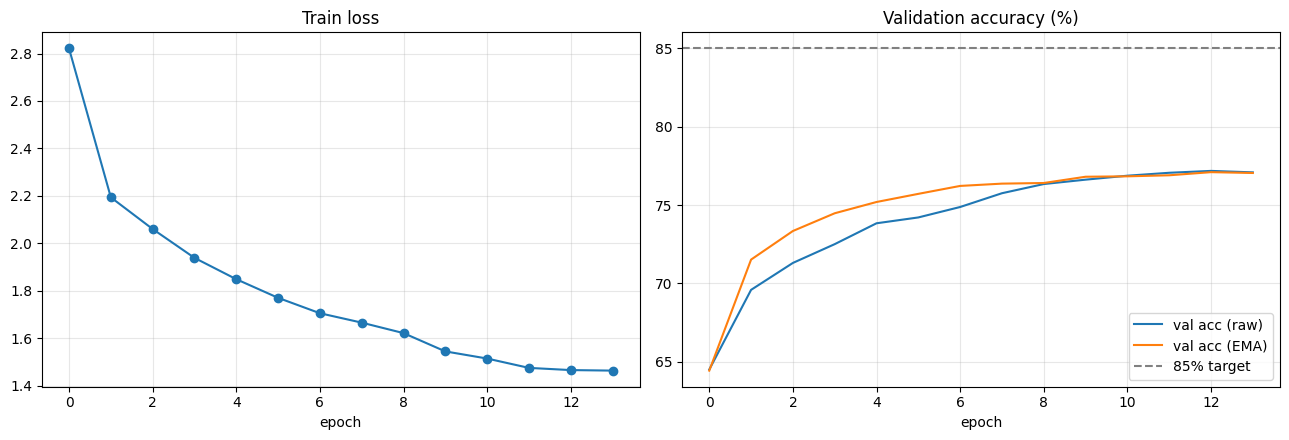

10 weakest validation classes (by F1):
                       class  precision  recall    f1  val_images
  Polyphagotars onemus latus      0.500   0.125 0.200           8
                   green bug      0.258   0.250 0.254          32
               large cutworm      0.316   0.245 0.276          49
therioaphis maculata Buckton      0.500   0.192 0.278          26
        bird cherry-oataphid      0.435   0.282 0.342          71
         white margined moth      0.333   0.357 0.345          14
                    beet fly      0.364   0.400 0.381          10
              yellow cutworm      0.447   0.354 0.395          48
         english grain aphid      0.500   0.369 0.425          65
        Nipaecoccus vastalor      0.750   0.300 0.429          10


In [12]:
# Cell 12: Learning curves + weakest classes
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(history["train_loss"], marker="o"); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch"); ax[0].grid(alpha=.3)
ax[1].plot(np.array(history["val_acc_raw"]) * 100, label="val acc (raw)")
ax[1].plot(np.array(history["val_acc_ema"]) * 100, label="val acc (EMA)")
ax[1].axhline(85, ls="--", c="gray", label="85% target"); ax[1].set_title("Validation accuracy (%)"); ax[1].set_xlabel("epoch")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "ip102_curves.png", dpi=200); plt.show()

pred = val_logits.argmax(1).numpy(); yn = yv.numpy()
p, r, f, s = precision_recall_fscore_support(yn, pred, labels=list(range(NUM_CLASSES)), zero_division=0)
rep = pd.DataFrame({"class": [class_names_map[i] for i in range(NUM_CLASSES)], "precision": p, "recall": r, "f1": f, "val_images": s})
rep.to_csv(OUTPUT_DIR / "ip102_per_class_val.csv", index=False)
print("10 weakest validation classes (by F1):")
print(rep[rep.val_images > 0].sort_values("f1").head(10).round(3).to_string(index=False))


             IP102 CLASSIFICATION EVALUATION

TRAINING AND VALIDATION ACCURACY
---------------------------------------------------------------------------
Training Accuracy   : 90.46%
Validation Accuracy : 77.33%

COMPLETE CLASSIFICATION METRICS
---------------------------------------------------------------------------
Training Accuracy                            : 90.46%
Validation Accuracy                          : 77.33%
Accuracy                                     : 77.33%
Precision                                    : 77.33%
Recall                                       : 77.33%
F1-Score                                     : 77.33%
Macro Precision                              : 71.83%
Macro Recall                                 : 68.95%
Macro F1-Score                               : 69.82%
Weighted Precision                           : 76.87%
Weighted Recall                              : 77.33%
Weighted F1-Score                            : 76.85%
Top-1 Accuracy               

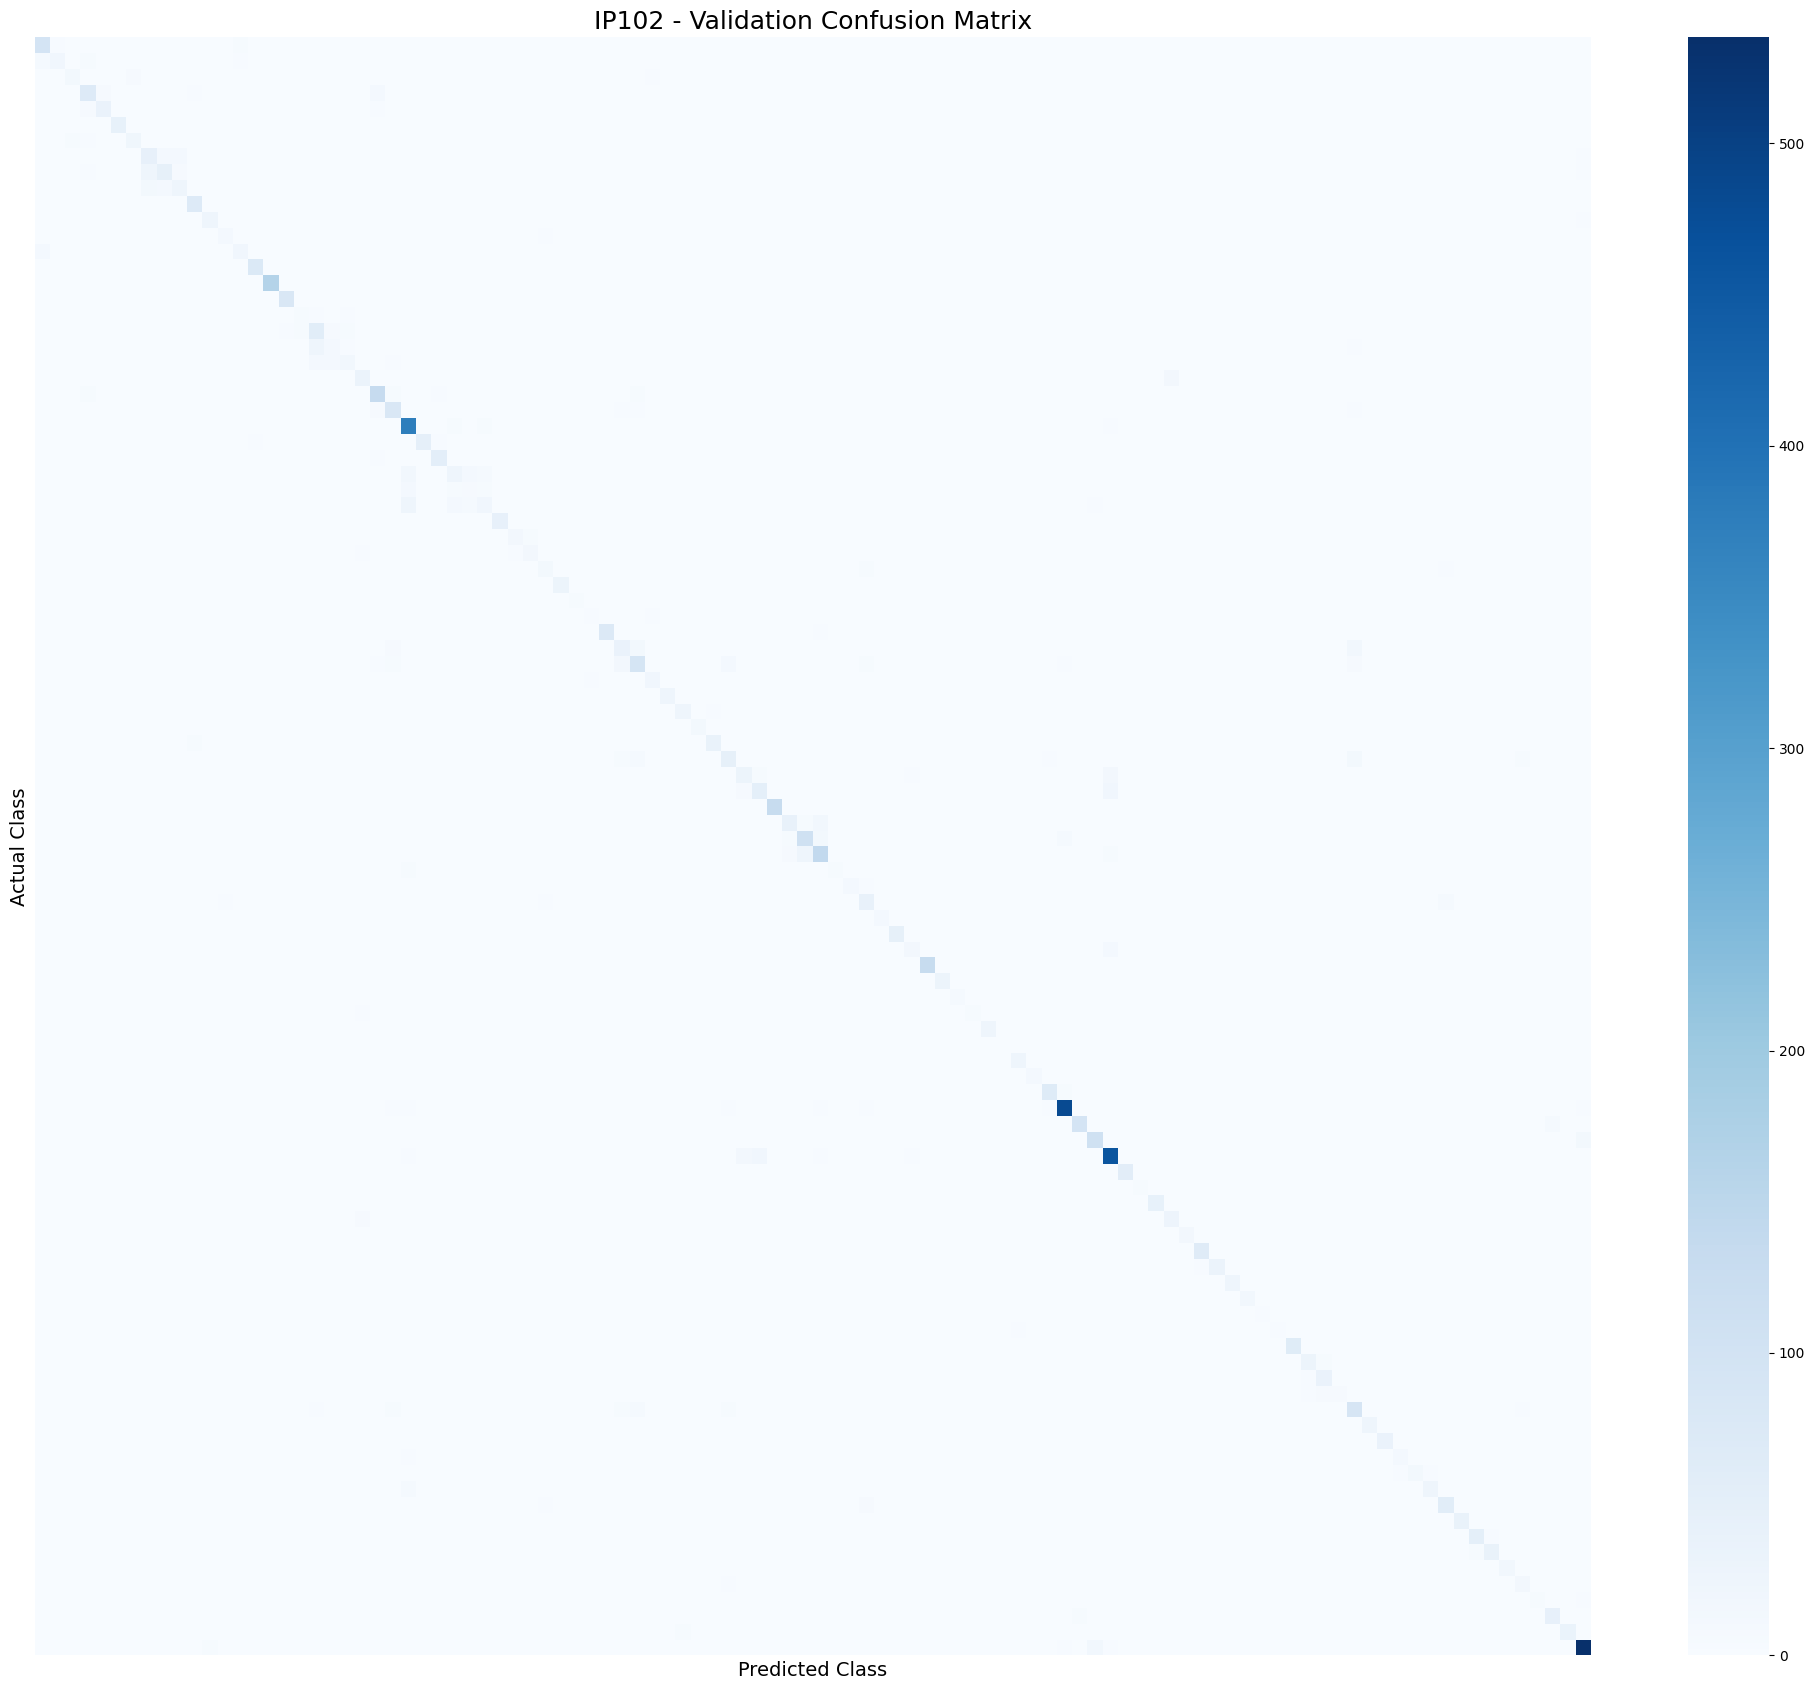


EVALUATION COMPLETED SUCCESSFULLY

Saved Files:
1. ip102_classification_metrics.csv
2. ip102_classification_metrics.json
3. ip102_confusion_matrix.csv
4. ip102_confusion_matrix.png

Output Directory: /kaggle/working/IP102_Results/classification

Training Accuracy  : 90.46%
Validation Accuracy: 77.33%



In [13]:

# ============================================================
# CELL 13: IP102 COMPLETE CLASSIFICATION EVALUATION
# Training Accuracy + Validation Accuracy + 15 Metrics
# ============================================================

import numpy as np
import pandas as pd
import json
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    cohen_kappa_score,
    matthews_corrcoef
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

# Use your existing trained model and training DataLoader.
# Change these two names if your notebook uses different names.

MODEL = model
TRAIN_LOADER = train_loader

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NUM_CLASSES = NUM_CLASSES

device = next(MODEL.parameters()).device

# ------------------------------------------------------------
# 2. CALCULATE TRAINING ACCURACY
# ------------------------------------------------------------

def calculate_training_predictions(model, loader, device):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for batch in loader:

            images, labels = batch[:2]

            images = images.to(device)

            outputs = model(images)

            # Support models returning tuples or dictionaries
            if isinstance(outputs, (tuple, list)):
                outputs = outputs[0]

            elif isinstance(outputs, dict):
                outputs = outputs["logits"]

            predictions = outputs.argmax(dim=1)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_predictions)
    )


y_train, train_predictions = calculate_training_predictions(
    MODEL,
    TRAIN_LOADER,
    device
)

train_accuracy = accuracy_score(
    y_train,
    train_predictions
)

# ------------------------------------------------------------
# 3. PREPARE VALIDATION PREDICTIONS
# ------------------------------------------------------------

if torch.is_tensor(val_logits):
    val_logits_np = val_logits.detach().cpu().numpy()
else:
    val_logits_np = np.asarray(val_logits)

if torch.is_tensor(yv):
    y_true = yv.detach().cpu().numpy()
else:
    y_true = np.asarray(yv)

y_true = y_true.astype(int)

val_predictions = np.argmax(
    val_logits_np,
    axis=1
)

val_accuracy = accuracy_score(
    y_true,
    val_predictions
)

# ------------------------------------------------------------
# 4. TOP-1 AND TOP-5 ACCURACY
# ------------------------------------------------------------

top1_accuracy = accuracy_score(
    y_true,
    val_predictions
)

top5_predictions = np.argsort(
    val_logits_np,
    axis=1
)[:, -5:]

top5_accuracy = np.mean([
    y_true[i] in top5_predictions[i]
    for i in range(len(y_true))
])

# ------------------------------------------------------------
# 5. CALCULATE ALL CLASSIFICATION METRICS
# ------------------------------------------------------------

metrics = {

    # Training and Validation
    "Training Accuracy": train_accuracy,
    "Validation Accuracy": val_accuracy,

    # Overall Classification Metrics
    "Accuracy": val_accuracy,

    "Precision": precision_score(
        y_true, val_predictions,
        average="micro",
        zero_division=0
    ),

    "Recall": recall_score(
        y_true, val_predictions,
        average="micro",
        zero_division=0
    ),

    "F1-Score": f1_score(
        y_true, val_predictions,
        average="micro",
        zero_division=0
    ),

    # Macro Metrics
    "Macro Precision": precision_score(
        y_true, val_predictions,
        average="macro",
        zero_division=0
    ),

    "Macro Recall": recall_score(
        y_true, val_predictions,
        average="macro",
        zero_division=0
    ),

    "Macro F1-Score": f1_score(
        y_true, val_predictions,
        average="macro",
        zero_division=0
    ),

    # Weighted Metrics
    "Weighted Precision": precision_score(
        y_true, val_predictions,
        average="weighted",
        zero_division=0
    ),

    "Weighted Recall": recall_score(
        y_true, val_predictions,
        average="weighted",
        zero_division=0
    ),

    "Weighted F1-Score": f1_score(
        y_true, val_predictions,
        average="weighted",
        zero_division=0
    ),

    # Top-K Accuracy
    "Top-1 Accuracy": top1_accuracy,
    "Top-5 Accuracy": top5_accuracy,

    # Agreement Metrics
    "Cohen's Kappa": cohen_kappa_score(
        y_true, val_predictions
    ),

    "Matthews Correlation Coefficient (MCC)": matthews_corrcoef(
        y_true, val_predictions
    )
}

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("             IP102 CLASSIFICATION EVALUATION")
print("=" * 75)

print("\nTRAINING AND VALIDATION ACCURACY")
print("-" * 75)

print(f"Training Accuracy   : {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy : {val_accuracy * 100:.2f}%")

print("\nCOMPLETE CLASSIFICATION METRICS")
print("-" * 75)

for name, value in metrics.items():

    if name in [
        "Cohen's Kappa",
        "Matthews Correlation Coefficient (MCC)"
    ]:
        print(f"{name:<45}: {value:.4f}")

    else:
        print(f"{name:<45}: {value * 100:.2f}%")

print("=" * 75)

# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    val_predictions,
    labels=np.arange(NUM_CLASSES)
)

# Save confusion matrix CSV
pd.DataFrame(cm).to_csv(
    OUTPUT_DIR / "ip102_confusion_matrix.csv",
    index=False
)

# Plot confusion matrix
plt.figure(figsize=(20, 17))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=False,
    yticklabels=False,
    cbar=True
)

plt.title(
    "IP102 - Validation Confusion Matrix",
    fontsize=18
)

plt.xlabel("Predicted Class", fontsize=14)
plt.ylabel("Actual Class", fontsize=14)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "ip102_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. SAVE METRICS TO CSV
# ------------------------------------------------------------

metrics_df = pd.DataFrame([
    {
        "Metric": name,
        "Score": round(float(value), 6),
        "Percentage": round(float(value) * 100, 2)
    }
    for name, value in metrics.items()
])

metrics_df.to_csv(
    OUTPUT_DIR / "ip102_classification_metrics.csv",
    index=False
)

# ------------------------------------------------------------
# 9. SAVE METRICS TO JSON
# ------------------------------------------------------------

with open(
    OUTPUT_DIR / "ip102_classification_metrics.json",
    "w"
) as f:

    json.dump(
        {
            name: float(value)
            for name, value in metrics.items()
        },
        f,
        indent=4
    )

# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\nEVALUATION COMPLETED SUCCESSFULLY")

print("\nSaved Files:")
print("1. ip102_classification_metrics.csv")
print("2. ip102_classification_metrics.json")
print("3. ip102_confusion_matrix.csv")
print("4. ip102_confusion_matrix.png")

print("\nOutput Directory:", OUTPUT_DIR)
print("\nTraining Accuracy  : {:.2f}%".format(
    train_accuracy * 100
))

print("Validation Accuracy: {:.2f}%".format(
    val_accuracy * 100
))

print("\n" + "=" * 75)
